In [1]:
using LinearAlgebra
using Plots
using Printf
using LaTeXStrings

using Distributed

BLAS.set_num_threads(1)
addprocs(71, enable_threaded_blas=false);

┌ Info: Precompiling Plots [91a5bcdd-55d7-5caf-9e0b-520d859cae80]
└ @ Base loading.jl:1260


In [2]:
gr();
# pyplot();
# plotlyjs();

# Generalization of @Ahmadian2015 to partially symmetric $J$

In @Ahmadian2015 it is shown that for the $N \times N$ matrix $A = M + L J R$, with $M, L, R$ fixed and $J$ random with $N \langle J_{ij} J_{kl}^* \rangle_J = \delta_{ik} \delta_{jl}$, the eigenvalue distribution has support in the region of the complex $z$-plane where
$$
1 \le \operatorname{tr}\left[(M_z M_z^\dagger)^{-1} \right] \, ,
$$
where $M_z = L^{-1} (zI - M) R^{-1}$. In particular, the equality is satisfied at the boundary of the support. This holds in the limit of large $N$. There are caveats about order of limits that we won't worry about now.

I just derived a generalization to the case where we also have correlations $N \langle J_{ij} J_{kl} \rangle_J = \tau \delta_{il} \delta_{jk}$, enforcing some degree of hermiticity in $J$---in particular, with $\tau = \pm 1$ the matrix is (anti-)hermitian. Within the spectral support, the following system of equations has a solution with $g^2 > 0$:
$$
\begin{aligned}
1 &= \mathcal{K}(g, z) = \operatorname{tr} \left[ \left(Q_z Q_z^\dagger + g^2 I \right)^{-1}\right] \, , \\
q &= \tau \operatorname{tr} \left[ Q_z^\dagger \left(Q_z Q_z^\dagger + g^2 I\right)^{-1} \right] \, ,
\end{aligned}
$$
where,
$$
Q_z = M_z - q I \, .
$$

The equation for $q$ has multiple solutions. To find the correct one, we start at very large $g^2$. In this limit, we have,
$$
\lim_{g \rightarrow \infty} q = \tau g^{-2} \operatorname{tr} M_z^\dagger \, .
$$
Using this initialization, the strategy is to iteratively lower $g^2$ and calculate the corresponding $q$. We keep doing this until we encounter a $g^2$ such that $\mathcal{K}(g, z) = 1$. If no such value is found, $z$ is outside the spectral support of $A$.

In [3]:
@everywhere using Revise
@everywhere push!(LOAD_PATH, pwd())
using RMTProblems  # Load on a single node first in case recompilation is needed
using RMTSolver    # Load on a single node first in case recompilation is needed
@everywhere workers() using RMTProblems
@everywhere workers() using RMTSolver

┌ Info: Precompiling RMTProblems [top-level]
└ @ Base loading.jl:1260
┌ Info: Precompiling RMTSolver [top-level]
└ @ Base loading.jl:1260


In [100]:
N = 1000
N_reduced = 4
σ = 0.95
u = 0.6

problem = rmt_problems[3](N=N, σ=σ)  #, u=u)
problem_reduced = rmt_problems[3](N=N_reduced, σ=σ)  #, u=u)

τabs = 0.5
θ = 0.0  # pi / 6
if θ == 0.0
    τ = τabs
else
    τ = τabs * exp(2im * θ)
end

0.5

In [101]:
using RMTUtils

Mevs = unique(eigvals(problem.M))

# Jr = (1 / sqrt(N)) * randn(N, N)
# # Jr = (1 / sqrt(N)) * rand([-1.0; 1.0], (N, N))
# Jr = partially_hermitize(Jr, τ)
# LJrR = problem.L * Jr * problem.R
# Ar = problem.M + LJrR

# Arevs = eigvals(Ar)
# Jrevs = eigvals(Jr);

Jc = (1 / sqrt(2N)) * (randn(N, N) + im * randn(N, N))
Jc = partially_hermitize(Jc, τ)
LJcR = problem.L * Jc * problem.R
Ac = problem.M + LJcR

Acevs = eigvals(Ac)
Jcevs = eigvals(Jc);

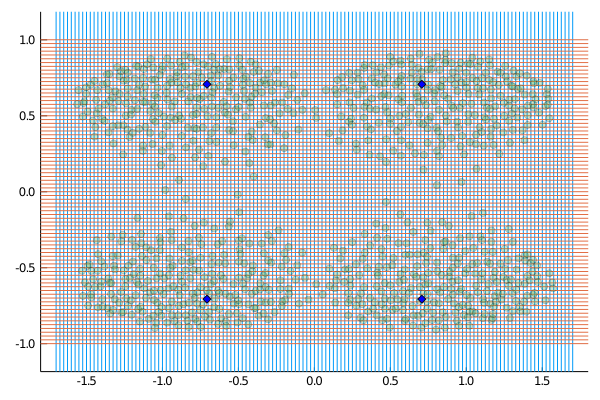

In [140]:
xs = -1.7:0.025:1.7
ys = -1.0:0.025:1.0

vline(xs, label="")
hline!(ys, label="")
# scatter!(real(Arevs), imag(Arevs), alpha=0.25, aspect_ratio=:equal, label="")
scatter!(real(Acevs), imag(Acevs), alpha=0.25, aspect_ratio=:equal, label="")
scatter!(real(Mevs), imag(Mevs), markershape=:diamond, markercolor=:blue, label="")

In [103]:
b = 4.0 / 3.0
n = 17

dτ = 0.025

gsq_solver, K_solver = rmt_solvers(problem=problem_reduced, τ=τ, dτ=dτ, b=b, n=n);

In [104]:
z = -1.675 + 0.000im

q, gsq, gsq_seq, q_seq, K_seq = gsq_solver(z, verbose=true);
# q, K, τ_seq, q_seq, K_seq = K_solver(z, verbose=true);

  z = -1.675 + i 0.000
--------------------------------------------
   g^2               q                K
--------------------------------------------
 1.31e+02  -6.42e-03 + i-1.08e-19   7.37e-03
 9.82e+01  -8.48e-03 + i 0.00e+00   9.77e-03
 7.33e+01  -1.12e-02 + i 2.16e-19   1.29e-02
 5.46e+01  -1.46e-02 + i 0.00e+00   1.71e-02
 4.05e+01  -1.91e-02 + i 4.29e-19   2.25e-02
 3.00e+01  -2.48e-02 + i-1.14e-20   2.94e-02
 2.21e+01  -3.19e-02 + i 4.34e-19   3.85e-02
 1.62e+01  -4.07e-02 + i 0.00e+00   5.00e-02
 1.18e+01  -5.15e-02 + i 1.73e-18   6.47e-02
 8.52e+00  -6.45e-02 + i 8.67e-19   8.33e-02
 6.06e+00  -7.99e-02 + i-1.73e-18   1.07e-01
 4.22e+00  -9.79e-02 + i 1.73e-18   1.36e-01
 2.85e+00  -1.19e-01 + i 1.73e-18   1.74e-01
 1.84e+00  -1.43e-01 + i 3.47e-18   2.21e-01
 1.10e+00  -1.72e-01 + i 5.20e-18   2.81e-01
 5.60e-01  -2.04e-01 + i-6.94e-18   3.59e-01
 1.76e-01  -2.42e-01 + i-3.12e-17   4.60e-01
-9.10e-02  -2.86e-01 + i-1.39e-17   5.93e-01
-2.70e-01  -3.36e-01 + i-3.47e-17   7

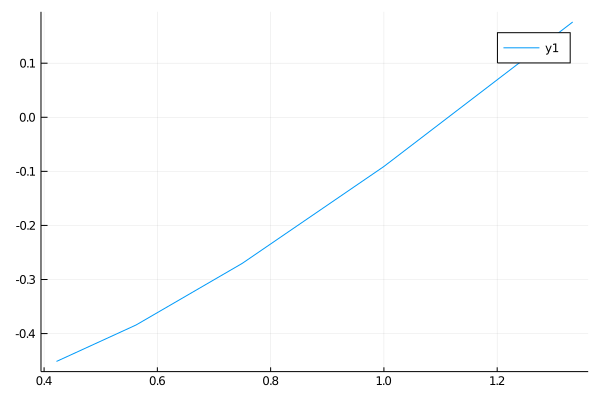

In [105]:
# plot(gsq_seq, K_seq)

plot(b.^(1:-1:-(length(gsq_seq) - 1 - n)), gsq_seq[n:end])

# plot(τ_seq, K_seq)

In [106]:
@everywhere gsq_solver, K_solver = rmt_solvers(
    problem=$problem_reduced, τ=$τ, dτ=$dτ, b=$b, n=$n
)

In [107]:
zs = [complex(x, y) for y in ys, x in xs]
q_gsqs = pmap(gsq_solver, zs);
# q_Ks = pmap(K_solver, zs);

      From worker 32:	  z = -1.700 + i-0.975
      From worker 12:	  z = -1.700 + i-1.000
      From worker 16:	  z = -1.700 + i-0.825
      From worker 53:	  z = -1.700 + i-0.800
      From worker 30:	  z = -1.700 + i-0.750
      From worker 31:	  z = -1.700 + i-0.650
      From worker 7:	  z = -1.700 + i-0.625
      From worker 35:	  z = -1.700 + i-0.775
      From worker 21:	  z = -1.700 + i-0.575
      From worker 40:	  z = -1.700 + i-0.450
      From worker 56:	  z = -1.700 + i-0.350
      From worker 65:	  z = -1.700 + i-0.850
      From worker 19:	  z = -1.700 + i-0.950
      From worker 66:	  z = -1.700 + i-0.125
      From worker 68:	  z = -1.700 + i-0.075
      From worker 44:	  z = -1.700 + i-0.925
      From worker 58:	  z = -1.700 + i-0.875
      From worker 10:	  z = -1.700 + i-0.900
      From worker 39:	  z = -1.700 + i-0.725
      From worker 63:	  z = -1.700 + i-0.700
      From worker 45:	  z = -1.700 + i 0.175
      From worker 10:	  q = -3.91e-01 + i 3.38e-01
     

Excessive output truncated after 524318 bytes.

      From worker 69:	  z =  0.225 + i 0.050
      From worker 69:	  q = -2.56e-05 + i 5.03e-03
      From worker 69:	g^2 = -4.87e-02
      From worker 69:	  z =  0.250 + i-0.400
      From worker 69:	  q = -1.51e-02 + i 2.85e-02
      From worker 69:	g^2 =  1.37e-01
      From worker 69:	  z =  0.275 + i-0.700
      From worker 69:	  q = -2.71e-02 + i 2.01e-01
      From worker 69:	g^2 =  1.53e-01
      From worker 69:	  z =  0.300 + i-0.900
      From worker 69:	  q = -2.93e-02 + i 3.61e-01
      From worker 69:	g^2 = -1.27e-01
      From worker 69:	  z =  0.300 + i 0.900
      From worker 69:	  q = -2.93e-02 + i-3.61e-01
      From worker 69:	g^2 = -1.27e-01
      From worker 69:	  z =  0.325 + i 0.675
      From worker 69:	  q = -1.74e-02 + i-1.80e-01
      From worker 69:	g^2 =  1.97e-01
      From worker 69:	  z =  0.350 + i 0.225
      From worker 69:	  q =  1.04e-02 + i 1.57e-02
      From worker 69:	g^2 =  6.81e-02
      From worker 69:	  z =  0.375 + i-0.150
      From worker

In [108]:
gsqs = similar(zs, Float64)
# Ks = similar(zs, Float64)
qs = similar(zs)
for i in 1:length(xs)
    for j in 1:length(ys)
        qs[j, i], gsqs[j, i] = q_gsqs[j, i]
        # qs[j, i], Ks[j, i] = q_Ks[j, i]
    end
end

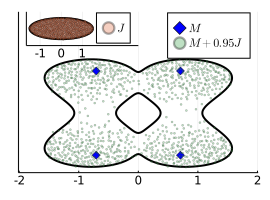

In [130]:
p = contour(
    xs,
    ys,
    gsqs,
    levels=[0.0],
    # Ks,
    # levels=[1.0],
    linewidth=2,
    color=:black,
    colorbar_entry=false,
    aspect_ratio=:equal,
    size=(270, 200),
    ylims=(-1.0, 1.7),
    yticks=[],
    # xlabel=L"\mathrm{Re}",
    # ylabel=L"\mathrm{Im}",
)
scatter!(
    p,
    real(Mevs),
    imag(Mevs),
    markershape=:diamond,
    markercolor=:blue,
    aspect_ratio=:equal,
    label=L"M",
)

plot!(
    p,
    t -> (1 + τabs) * cos(θ) * cos(t) - (1 - τabs) * sin(θ) * sin(t),
    t -> (1 + τabs) * sin(θ) * cos(t) + (1 - τabs) * cos(θ) * sin(t),
    0,
    2pi,
    linewidth=2,
    color=:black,
    aspect_ratio=:equal,
    label="",
    xlims=(-1.65, 3.65),
    xticks=[-1; 0; 1],
    yticks=[],
    inset_subplots=(1, bbox(0.033, 0.0, 0.467, 0.21)),
    subplot=2,
)

savefig(p, "boundary-complex.pdf")

scatter!(
    p,
    # real(Arevs),
    # imag(Arevs),
    real(Acevs),
    imag(Acevs),
    markersize=1.15,
    alpha=1.0 / 3.0,
    aspect_ratio=:equal,
    label=L"M + 0.95 J",
    subplot=1,
)

scatter!(
    p,
    # real(Jrevs),
    # imag(Jrevs),
    real(Jcevs),
    imag(Jcevs),
    markersize=1.15,
    alpha=1.0 / 3.0,
    aspect_ratio=:equal,
    label=L"J",
    subplot=2,
)

savefig(p, "spectrum-complex.pdf")
p

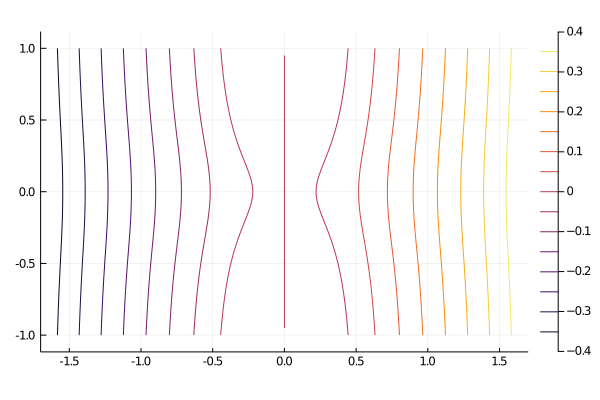

In [127]:
contour(xs, ys, real(qs), aspect_ratio=:equal)

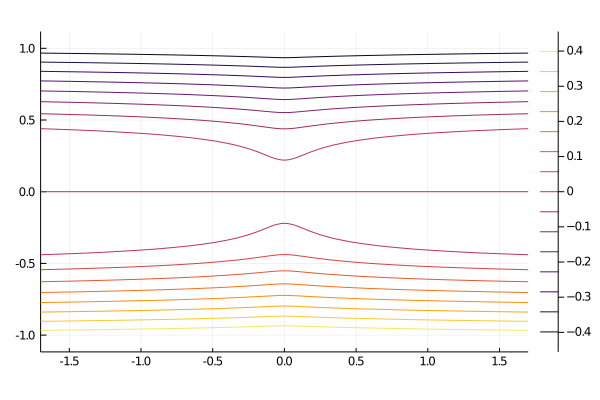

In [128]:
contour(xs, ys, imag(qs), aspect_ratio=:equal)

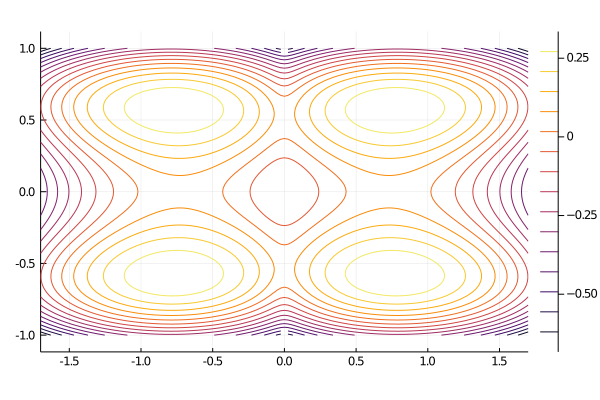

In [129]:
contour(xs, ys, gsqs, aspect_ratio=:equal)
# contour(xs, ys, Ks, aspect_ratio=:equal)

In [569]:
N = 1000
Jr_asym = (1 / sqrt(N)) * randn(N, N)

ps = []

for τabs in 0.0:0.3:0.9
    θ = 0.0  # pi / 6
    if θ == 0.0
        τ = τabs
    else
        τ = τabs * exp(2im * θ)
    end

    Jr = partially_hermitize(Jr_asym, τ)
    Jrevs = eigvals(Jr);

    p = plot(
        t -> (1 + τabs) * cos(θ) * cos(t) - (1 - τabs) * sin(θ) * sin(t),
        t -> (1 + τabs) * sin(θ) * cos(t) + (1 - τabs) * cos(θ) * sin(t),
        0,
        2pi,
        linewidth=2,
        color=:black,
        label="",
        aspect_ratio=:equal,
        size=(300, 75),
        xlims=(-2.2, 6.6),
        ylims=(-1.1, 1.1),
        xticks=[],
        yticks=[],
        showaxis=false,
    )

    savefig(p, @sprintf("boundary-ellipse-0%1.0f.pdf", 10 * τabs))

    scatter!(
        p,
        real(Jrevs),
        imag(Jrevs),
        markersize=1.15,
        alpha=1.0 / 3.0,
        label=latexstring("\\tau = $τ"),
        aspect_ratio=:equal,
    )

    savefig(p, @sprintf("spectrum-ellipse-0%1.0f.pdf", 10 * τabs))
    
    push!(ps, p)
end

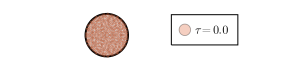

In [570]:
ps[1]

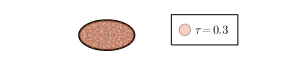

In [571]:
ps[2]

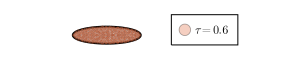

In [572]:
ps[3]

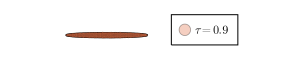

In [573]:
ps[4]